In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [5]:
def getRcAndErr(df):
    nos = sum(df[df.b==-1]['w'])
    nss = sum(df[df.b==+1]['w'])
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n_array = []
    wtot_array = []
    for i in range(0, len(w_array)):
        n_array.append( df[df.w == w_array[i]].shape[0] )
        wtot_array.append( sum(df[df.w == w_array[i]]['w']) )
    n = 0
    for i in range(0, len(w_array)):
        if (wtot_array[i] != 0):
            n += wtot_array[i]*n_array[i]/sum(wtot_array)
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err

In [38]:
def getRcsAndErrs(df):
    nos = sum(df[df.bs==-1]['w'])
    nss = sum(df[df.bs==+1]['w'])
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n_array = []
    wtot_array = []
    for i in range(0, len(w_array)):
        n_array.append( df[df.w == w_array[i]].shape[0] )
        wtot_array.append( sum(df[df.w == w_array[i]]['w']) )
    n = 0
    for i in range(0, len(w_array)):
        if (wtot_array[i] != 0):
            n += wtot_array[i]*n_array[i]/sum(wtot_array)
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err

In [6]:
def getRcsData(dataframe):
    n_ss = dataframe[dataframe.bs==1].shape[0]
    n_os = dataframe[dataframe.bs==-1].shape[0]
    return (n_ss-n_os)/(n_ss+n_os)

In [7]:
def getRcsErrData(dataframe):
    n_ss = dataframe[dataframe.bs==1].shape[0]
    n_os = dataframe[dataframe.bs==-1].shape[0]
    p = n_ss/(n_ss+n_os)
    return 2*np.sqrt(p*(1-p)/(n_ss+n_os))

In [8]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [9]:
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = '15'

In [10]:
observables1 = ['pt','b','dr','z','epair','pt1','pt2','reject','w']
observabless1 = ['pts','bs','drs','zs','epairs','pt1s','pt2s','rejects','ws']

In [25]:
df_geant = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all_pid_new.root', "MatchedTree"),'bs!=-9 and bs!=0 and pts>15 and reject<=0 and rejects<=0')

In [42]:
df_geant.shape[0]

38601

In [43]:
w_array = np.unique(df_geant['w'])

In [44]:
df_geant_array = [ df_geant[(df_geant.pts>20) & (df_geant.pts<25)],\
                    df_geant[(df_geant.pts>25) & (df_geant.pts<30)],\
                    df_geant[(df_geant.pts>30) & (df_geant.pts<40)] ]

In [45]:
rc_geant_array = []
rc_err_geant_array = []
for i in range(0, len(df_geant_array)):
    rc_geant_array.append(getRcsAndErrs(df_geant_array[i])[0])
    rc_err_geant_array.append(getRcsAndErrs(df_geant_array[i])[1])

In [46]:
rc_geant_array

[-0.3833092465884145, -0.36009438178075104, -0.38591533291818914]

In [47]:
rc_err_geant_array

[0.017631789265509484, 0.019034323343522983, 0.02367379087999921]

In [24]:
df0 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_50pthat_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df1 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_45pthat50_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df2 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_40pthat45_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df3 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_35pthat40_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df4 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_30pthat35_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df5 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_25pthat30_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df6 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_20pthat25_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df7 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_15pthat20_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df8 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_11pthat15_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df9 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_10pthat11_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)

In [32]:
w0=(float)(df0.iloc[df0.shape[0]-1]['xsec'])/200000
w1=(float)(df1.iloc[df1.shape[0]-1]['xsec'])/200000
w2=(float)(df2.iloc[df2.shape[0]-1]['xsec'])/200000
w3=(float)(df3.iloc[df3.shape[0]-1]['xsec'])/200000
w4=(float)(df4.iloc[df4.shape[0]-1]['xsec'])/200000
w5=(float)(df5.iloc[df5.shape[0]-1]['xsec'])/200000
w6=(float)(df6.iloc[df6.shape[0]-1]['xsec'])/200000
w7=(float)(df7.iloc[df7.shape[0]-1]['xsec'])/200000
w8=(float)(df8.iloc[df8.shape[0]-1]['xsec'])/200000
w9=(float)(df9.iloc[df9.shape[0]-1]['xsec'])/200000
df0['w']=np.ones(df0.shape[0])*w0
df1['w']=np.ones(df1.shape[0])*w1
df2['w']=np.ones(df2.shape[0])*w2
df3['w']=np.ones(df3.shape[0])*w3
df4['w']=np.ones(df4.shape[0])*w4
df5['w']=np.ones(df5.shape[0])*w5
df6['w']=np.ones(df6.shape[0])*w6
df7['w']=np.ones(df7.shape[0])*w7
df8['w']=np.ones(df8.shape[0])*w8
df9['w']=np.ones(df9.shape[0])*w9
df = pd.concat([df0,df1,df2,df3,df4,df5,df6,df7,df8,df9])
df_fastsim = df[['pts','bs','w']]
df_fastsim = applyCut(df_fastsim, 'bs!=-9 and bs!=0 and pts>15')

In [34]:
df_fastsim.shape[0]

604713

In [49]:
w_array = np.unique(df_fastsim['w'])

In [50]:
df_fastsim_array = [ df_fastsim[(df_fastsim.pts>20) & (df_fastsim.pts<25)],\
                    df_fastsim[(df_fastsim.pts>25) & (df_fastsim.pts<30)],\
                    df_fastsim[(df_fastsim.pts>30) & (df_fastsim.pts<40)] ]

In [51]:
rc_fastsim_array = []
rc_err_fastsim_array = []
for i in range(0, len(df_fastsim_array)):
    rc_fastsim_array.append(getRcsAndErrs(df_fastsim_array[i])[0])
    rc_err_fastsim_array.append(getRcsAndErrs(df_fastsim_array[i])[1])

In [52]:
rc_fastsim_array

[-0.379513398659859, -0.419019764400406, -0.4136115031105032]

In [53]:
rc_err_fastsim_array

[0.00971777552139196, 0.009269671845334585, 0.007051871467307714]

In [59]:
df0 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/pythia_50pthat_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df1 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/pythia_45pthat50_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df2 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/pythia_40pthat45_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df3 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/pythia_35pthat40_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df4 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/pythia_30pthat35_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df5 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/pythia_25pthat30_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df6 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/pythia_20pthat25_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df7 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/pythia_15pthat20_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df8 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/pythia_11pthat15_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)

In [60]:
w0=(float)(df0.iloc[df0.shape[0]-1]['xsec'])/200000
w1=(float)(df1.iloc[df1.shape[0]-1]['xsec'])/200000
w2=(float)(df2.iloc[df2.shape[0]-1]['xsec'])/200000
w3=(float)(df3.iloc[df3.shape[0]-1]['xsec'])/200000
w4=(float)(df4.iloc[df4.shape[0]-1]['xsec'])/200000
w5=(float)(df5.iloc[df5.shape[0]-1]['xsec'])/200000
w6=(float)(df6.iloc[df6.shape[0]-1]['xsec'])/200000
w7=(float)(df7.iloc[df7.shape[0]-1]['xsec'])/200000
w8=(float)(df8.iloc[df8.shape[0]-1]['xsec'])/200000
df0['w']=np.ones(df0.shape[0])*w0
df1['w']=np.ones(df1.shape[0])*w1
df2['w']=np.ones(df2.shape[0])*w2
df3['w']=np.ones(df3.shape[0])*w3
df4['w']=np.ones(df4.shape[0])*w4
df5['w']=np.ones(df5.shape[0])*w5
df6['w']=np.ones(df6.shape[0])*w6
df7['w']=np.ones(df7.shape[0])*w7
df8['w']=np.ones(df8.shape[0])*w8
df = pd.concat([df0,df1,df2,df3,df4,df5,df6,df7,df8])
df_fastsim_pythia = df[['pts','bs','w']]
df_fastsim_pythia = applyCut(df_fastsim_pythia, 'bs!=-9 and bs!=0 and pts>15')

In [61]:
w_array = np.unique(df_fastsim_pythia['w'])

In [62]:
df_fastsim_pythia_array = [ df_fastsim_pythia[(df_fastsim_pythia.pts>20) & (df_fastsim_pythia.pts<25)],\
                    df_fastsim_pythia[(df_fastsim_pythia.pts>25) & (df_fastsim_pythia.pts<30)],\
                    df_fastsim_pythia[(df_fastsim_pythia.pts>30) & (df_fastsim_pythia.pts<40)] ]

In [63]:
rc_fastsim_pythia_array = []
rc_err_fastsim_pythia_array = []
for i in range(0, len(df_fastsim_pythia_array)):
    rc_fastsim_pythia_array.append(getRcsAndErrs(df_fastsim_pythia_array[i])[0])
    rc_err_fastsim_pythia_array.append(getRcsAndErrs(df_fastsim_pythia_array[i])[1])

In [64]:
rc_fastsim_pythia_array

[-0.413625641706378, -0.4132547824850626, -0.41224449306746946]

In [65]:
rc_err_fastsim_pythia_array

[0.009738100697972386, 0.009437319411581907, 0.00726821285160157]

In [54]:
observables1 = ['pt','m','q2','rg','zg','mg','b']
file = uproot.open('/vast/palmer/home.grace/ys668/output/run12/data0415_pt10_m0_new.root')
tree = file["ResultTree"].arrays(observables1, library='np')
df = pd.DataFrame(np.transpose(np.array((np.concatenate(tree['pt']),np.concatenate(tree['b'])))), columns=["pts","bs"])
df_data = applyCut(df, 'bs!=0 and bs!=-9 and pts>15')

In [55]:
df_data_array = [ df_data[(df_data.pts>20) & (df_data.pts<25)],\
                    df_data[(df_data.pts>25) & (df_data.pts<30)],\
                    df_data[(df_data.pts>30) & (df_data.pts<40)] ]

In [56]:
rc_data_array = []
rc_err_data_array = []
for i in range(0, len(df_data_array)):
    rc_data_array.append(getRcsData(df_data_array[i]))
    rc_err_data_array.append(getRcsErrData(df_data_array[i]))

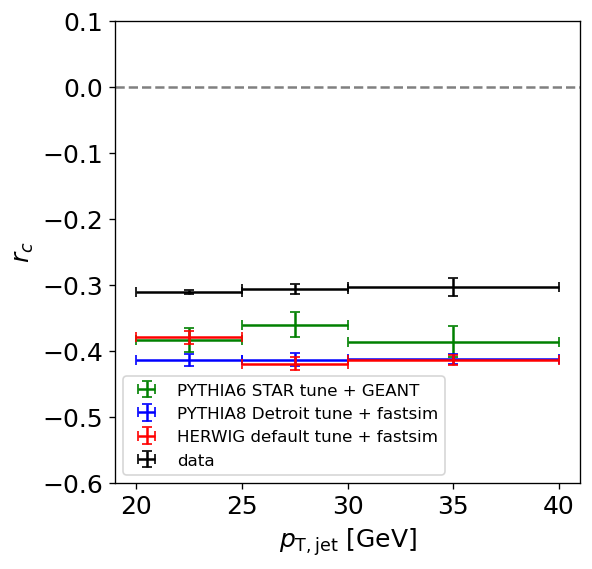

In [66]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_geant_array, xerr=[2.5, 2.5, 5], yerr=rc_err_geant_array, capsize=3, color='g', ls='none', label='PYTHIA6 STAR tune + GEANT')
plt.errorbar([22.5, 27.5, 35], rc_fastsim_pythia_array, xerr=[2.5, 2.5, 5], yerr=rc_err_fastsim_pythia_array, capsize=3, color='b', ls='none', label='PYTHIA8 Detroit tune + fastsim')
plt.errorbar([22.5, 27.5, 35], rc_fastsim_array, xerr=[2.5, 2.5, 5], yerr=rc_err_fastsim_array, capsize=3, color='r', ls='none', label='HERWIG default tune + fastsim')
plt.errorbar([22.5, 27.5, 35], rc_data_array, xerr=[2.5, 2.5, 5], yerr=rc_err_data_array, capsize=3, color='k', ls='none', label='data')
plt.xlabel('$p_{\mathrm{T, jet}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$r_c$')
plt.ylim(-0.6,0.1)
plt.legend(fontsize=10)

plot to be included in the prospectus

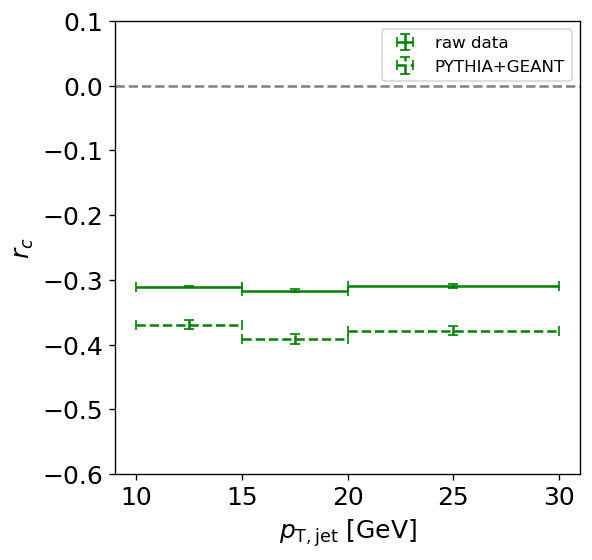

In [26]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([12.5, 17.5, 25], [rcs_0_data, rcs_1_data, rcs_2_data], xerr=[2.5, 2.5, 5], yerr=[rcs_err_0_data, rcs_err_1_data, rcs_err_2_data], capsize=3, color='g', ls='none', label='raw data')
eb1=plt.errorbar([12.5, 17.5, 25], [rcs_0, rcs_1, rcs_2], xerr=[2.5, 2.5, 5], yerr=[rcs_err_0, rcs_err_1, rcs_err_2], capsize=3, color='g', ls='none', label='PYTHIA+GEANT')
eb1[-1][0].set_linestyle('--')
eb1[-1][1].set_linestyle('--')
plt.xlabel('$p_{\mathrm{T, jet}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$r_c$')
plt.ylim(-0.6,0.1)
plt.legend(fontsize=10)
plt.savefig('rc.pdf', bbox_inches='tight')